# Task 1 - Multi-Class Benchmark Classification Pipeline (Iris)

Goal: predict the iris species from four flower measurements.

This is supervised classification. I already have the correct species for every row in `iris.csv`. I will train on most of the rows, then score the model on rows it has not seen.

- Features: `sepal_length`, `sepal_width`, `petal_length`, `petal_width` (cm)
- Target: `species` - `setosa`, `versicolor`, or `virginica`

By the end of this notebook I will have:

1. Loaded the data and checked it.
2. Plotted how the species separate.
3. Split the data 80/20 and scaled the features with `StandardScaler`.
4. Trained Logistic Regression and a Decision Tree.
5. Compared accuracy, precision, recall, and F1-score.
6. Plotted confusion matrix heatmaps and a decision boundary.


## Plan

1. Know the data - load `iris.csv` and check the columns, missing values, and how many flowers are in each species.
2. See how the species separate - pairplot of the four measurements, colored by species.
3. Split, then scale - 80% train / 20% test. Fit `StandardScaler` on the training rows only.
4. Train two models - Logistic Regression and Decision Tree.
5. Benchmark - accuracy, precision, recall, F1, and a classification report for both models.
6. See the mistakes - confusion matrix heatmaps and a decision boundary plot.


---

## Section 1 - Know the data

I want a clear look at the table before I scale anything or train a model.

1. Load `iris.csv`.
2. Look at a few rows.
3. Check the types, missing values, and the range of each measurement.
4. Count how many flowers belong to each species.

One row is one flower. Later the model takes the four measurements and predicts the species.


In [1]:
from pathlib import Path

import pandas as pd

# loading the dataset 
df = pd.read_csv("iris.csv")

#Displaying the loaded dataset
df
# Getting the shape of the data

print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")

Shape: 150 rows, 5 columns


### A few rows

The first rows are all `setosa`. The numbers are lengths and widths in cm. `species` is the label I want to predict.


In [2]:
# Displaying the first five rows of the loaded dataset 
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Column types

The four measurements are floats, which is what I need before scaling and training. `species` is text because it is a category, not a measurement.


In [3]:
# Checking the datatypes of the variables
df.dtypes

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object

### Missing values

If a measurement was missing I would have to handle it before scaling. I am counting missing values per column.


In [4]:
# Checking the missing values
df.isna().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

### How spread out each measurement is

`describe()` gives the count, mean, std, and the min to max range.

The columns are all in cm, but they do not spread the same way. Petal length runs from 1.0 to 6.9 (std about 1.77). Sepal width only runs from 2.0 to 4.4 (std about 0.44).A change of 1 cm is a small step for petal length and a big step for sepal width.

Logistic Regression uses a weighted sum of the four measurements. A column that swings more can push that sum harder just because its numbers are larger. In Section 3 I will scale each column with `(value - mean) / std`. I will take the mean and std from the training rows only, then apply those same numbers to the test rows.


In [5]:
# Summary of each measurement
df.describe().round(3)


,sepal_length,sepal_width,petal_length,petal_width
count,150.000,150.000,150.000,150.000
mean,5.843,3.057,3.758,1.199
std,0.828,0.436,1.765,0.762
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.350,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


### Class counts

There are three species. If one species had most of the rows, accuracy could look good just because the model always guessed the common one. I want to see whether the classes are balanced.


In [6]:
# How many flowers in each species
df["species"].value_counts().sort_index()


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

### What I have so far

- 150 flowers, 4 numeric features, 1 label.
- No missing values.
- `setosa`, `versicolor`, and `virginica`, 50 flowers each. The classes are balanced.
- The measurements have different spreads, so I will scale them after the train/test split.

Next I will plot every pair of measurements and color the points by species, so I can see which species separate and which ones overlap.


---

## Section 2 - See how the species separate

I have not trained a model yet. I want to see if the three species sit apart when I plot the measurements.

`sns.pairplot` draws every measurement against every other one. Each point is one flower, colored by species.

- The diagonal is one measurement on its own, split by species.
- Every other cell is two measurements plotted together.

If one color forms its own group, those measurements can separate that species. If two colors mix, those two species will be easier to confuse.


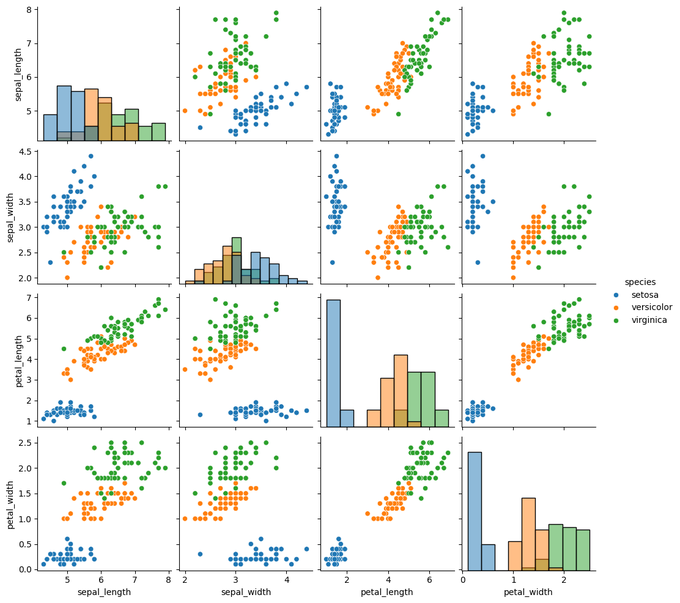

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Every pair of measurements, colored by species
sns.pairplot(df, hue="species", diag_kind="hist", height=1.6)
plt.show()


### What the pairplot shows

Setosa sits apart as soon as petal length or petal width is on an axis. Its petals are much smaller than the other two species.

Versicolor and virginica overlap. That mix is strongest on sepal length and sepal width. Petal length against petal width pulls them apart more, but the two groups still touch.

I am checking the average of each measurement by species below, to confirm what the plot is showing.


In [8]:
# Average of each measurement by species
df.groupby("species").mean().round(2)


,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


Setosa petal length averages 1.46 cm, versicolor 4.26 cm, and virginica 5.55 cm. Petal width follows the same order: 0.25, 1.33, then 2.03. Sepal width barely moves across species (3.43, 2.77, 2.97), which is why those points overlap.

Petal measurements should do most of the work when I train. I will still use all four columns. If a model gets a flower wrong, I expect that mistake to be versicolor vs virginica.

Next I will split the rows 80/20, then scale the four measurements with `StandardScaler` fit on the training rows only.


---

## Section 3 - Split, then scale

I need two things before I train:

1. A test set of flowers the model does not learn from, so the score is honest.
2. The four measurements on a shared scale, so a column with a wider spread does not push Logistic Regression harder just because its numbers are bigger.

`X` is the four measurements. `y` is the species. I scale `X` only. The species labels stay as they are.


In [9]:
# Features and the label
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X = df[feature_cols]
y = df["species"]

X.head()


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### Train and test split

I keep 80% of the rows to train and 20% to test.

- `test_size=0.2` is the 20% holdout. 150 rows gives 120 to train and 30 to test.
- `random_state=42` locks the shuffle, so the same rows land in each set every time I run this.
- `stratify=y` keeps the species mix. Each species has 50 flowers, so the test set gets 10 of each and the training set gets 40 of each.


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])
print()
print("Train species counts:")
print(y_train.value_counts().sort_index())
print()
print("Test species counts:")
print(y_test.value_counts().sort_index())


Train rows: 120
Test rows: 30

Train species counts:
species
setosa        40
versicolor    40
virginica     40
Name: count, dtype: int64

Test species counts:
species
setosa        10
versicolor    10
virginica     10
Name: count, dtype: int64


### Scale with the training rows only

For each column:

```text
scaled value = (value - training mean) / training std
```

`fit` calculates the mean and std. I fit on `X_train` only. `transform` then applies those same numbers to the training rows and to the test rows.

The test flowers must not affect the mean or the std. If they did, information from the test set would leak into the preparation step, and the later score would be a bit too kind.


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = pd.DataFrame(
    scaler.transform(X_train), columns=feature_cols, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=feature_cols, index=X_test.index
)

# Mean and std that the scaler learned from the training rows
pd.DataFrame(
    {"train_mean": scaler.mean_, "train_std": scaler.scale_},
    index=feature_cols,
).round(3)


,train_mean,train_std
sepal_length,5.842,0.837
sepal_width,3.048,0.447
petal_length,3.770,1.761
petal_width,1.205,0.759


Checking one training flower by hand. `scaled` comes from `StandardScaler`. `by_hand` is `(original - train_mean) / train_std`. The two columns should match.


In [12]:
# One training row, original vs scaled
original = X_train.iloc[0]
scaled = X_train_scaled.iloc[0]
by_hand = (original - scaler.mean_) / scaler.scale_

pd.DataFrame(
    {"original": original, "scaled": scaled, "by_hand": by_hand}
).round(3)


,original,scaled,by_hand
sepal_length,4.4,-1.722,-1.722
sepal_width,2.9,-0.332,-0.332
petal_length,1.4,-1.346,-1.346
petal_width,0.2,-1.323,-1.323


After scaling, each training column should have mean 0 and std 1. The test columns were scaled with the training mean and std, so their means will be close to 0, not exactly 0.


In [13]:
# Mean and std after scaling
pd.DataFrame(
    {
        "train_mean": X_train_scaled.mean(),
        "train_std": X_train_scaled.std(ddof=0),
        "test_mean": X_test_scaled.mean(),
        "test_std": X_test_scaled.std(ddof=0),
    }
).round(3)


,train_mean,train_std,test_mean,test_std
sepal_length,-0.0,1.0,0.010,0.925
sepal_width,0.0,1.0,0.101,0.849
petal_length,0.0,1.0,-0.034,0.995
petal_width,0.0,1.0,-0.037,1.001


### What I have so far

- 120 training flowers and 30 test flowers, 40 and 10 of each species.
- `X_train_scaled` and `X_test_scaled` use the training mean and training std.
- The species labels are still `y_train` and `y_test`.

---

## Section 4 - Train two models

Both models learn from the 120 scaled training flowers. The 30 test flowers stay out of training.

Logistic Regression learns a weight for each measurement, for each species. It multiplies the scaled measurements by those weights, adds them up, and turns the totals into a probability for setosa, versicolor, and virginica. The prediction is the species with the highest probability.

A Decision Tree learns yes/no questions. Each question looks at one measurement. A flower follows the questions until it reaches a species.


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Same training rows for both models
log_reg = LogisticRegression(random_state=42)
tree = DecisionTreeClassifier(random_state=42)

log_reg.fit(X_train_scaled, y_train)
tree.fit(X_train_scaled, y_train)

print("Logistic Regression trained")
print("Decision Tree trained, depth:", tree.get_depth())


Logistic Regression trained
Decision Tree trained, depth: 5


### Weights the Logistic Regression learned

Each row is a species. Each column is a measurement. There is also a starting score, the intercept.

A positive weight means a larger measurement pushes toward that species. A negative weight pushes away from it. These weights are on the scaled measurements, where 0 is the training average.


In [15]:
# One weight per measurement, plus a starting score for each species
weights = pd.DataFrame(
    log_reg.coef_, index=log_reg.classes_, columns=feature_cols
)
weights["intercept"] = log_reg.intercept_
weights.round(3)


,sepal_length,sepal_width,petal_length,petal_width,intercept
setosa,-1.089,1.024,-1.799,-1.686,-0.306
versicolor,0.536,-0.360,-0.204,-0.808,1.909
virginica,0.553,-0.664,2.003,2.494,-1.603


### Questions the Decision Tree learned

The printed tree uses scaled values, so a threshold of 0 means the training average. The last line converts the first question back into centimeters, which is easier to compare with the pairplot.


In [16]:
from sklearn.tree import export_text

# Questions, in scaled units
print(export_text(tree, feature_names=feature_cols))

# First question, converted back to cm
root = 0
feature_index = tree.tree_.feature[root]
threshold_cm = tree.tree_.threshold[root] * scaler.scale_[feature_index] + scaler.mean_[feature_index]
print(
    "First question in cm:",
    feature_cols[feature_index],
    "<=",
    round(threshold_cm, 2),
)


|--- petal_length <= -0.75
|   |--- class: setosa
|--- petal_length >  -0.75
|   |--- petal_width <= 0.59
|   |   |--- petal_length <= 0.67
|   |   |   |--- class: versicolor
|   |   |--- petal_length >  0.67
|   |   |   |--- sepal_length <= 0.37
|   |   |   |   |--- sepal_width <= -1.34
|   |   |   |   |   |--- class: virginica
|   |   |   |   |--- sepal_width >  -1.34
|   |   |   |   |   |--- class: versicolor
|   |   |   |--- sepal_length >  0.37
|   |   |   |   |--- class: virginica
|   |--- petal_width >  0.59
|   |   |--- petal_length <= 0.61
|   |   |   |--- sepal_width <= -0.11
|   |   |   |   |--- class: virginica
|   |   |   |--- sepal_width >  -0.11
|   |   |   |   |--- class: versicolor
|   |   |--- petal_length >  0.61
|   |   |   |--- class: virginica

First question in cm: petal_length <= 2.45


### Predictions on the test flowers

`predict` returns one species per test flower. The full accuracy, precision, recall, and F1 comparison comes in the next section. This preview is just to see that both models name a species.


In [17]:
# Species predicted for the 30 test flowers
y_pred_log = log_reg.predict(X_test_scaled)
y_pred_tree = tree.predict(X_test_scaled)

pd.DataFrame(
    {
        "actual": y_test.to_numpy(),
        "logistic_regression": y_pred_log,
        "decision_tree": y_pred_tree,
    }
).head(10)


,actual,logistic_regression,decision_tree
0,setosa,setosa,setosa
1,virginica,virginica,virginica
2,versicolor,versicolor,versicolor
3,versicolor,versicolor,versicolor
4,setosa,setosa,setosa
5,versicolor,versicolor,versicolor
6,setosa,setosa,setosa
7,setosa,setosa,setosa
8,virginica,virginica,virginica
9,versicolor,versicolor,versicolor


### What I have so far

- Logistic Regression and a Decision Tree, both fit on the 120 scaled training flowers.
- A weight table for the logistic model, and the questions the tree asks.
- `y_pred_log` and `y_pred_tree`, the species each model predicts for the 30 test flowers.

Next I will score both models with accuracy, precision, recall, and F1.


---

## Section 5 - Benchmark the two models

I score both models on the 30 test flowers only. These flowers were not used in training.

- Accuracy: the share of test flowers given the right species.
- Precision, for one species: of the flowers the model called that species, the share that really were.
- Recall, for one species: of the flowers that really are that species, the share the model found.
- F1: one number that stays high only when precision and recall are both high.

The test set has three species, so the precision, recall, and F1 in the comparison table are the average of the three species. Each species counts the same. That average is the macro average.


In [18]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)

def benchmark(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro"),
        "recall": recall_score(y_true, y_pred, average="macro"),
        "f1": f1_score(y_true, y_pred, average="macro"),
    }

# One column per model
comparison = pd.DataFrame(
    {
        "logistic_regression": benchmark(y_test, y_pred_log),
        "decision_tree": benchmark(y_test, y_pred_tree),
    }
).round(3)

comparison


,logistic_regression,decision_tree
accuracy,0.933,0.933
precision,0.933,0.933
recall,0.933,0.933
f1,0.933,0.933


The classification report breaks the same scores out by species. `support` is how many test flowers truly belong to that species. Here that is 10 for each species.


In [19]:
# Per-species precision, recall, and F1
print("Logistic Regression")
print(classification_report(y_test, y_pred_log))
print("Decision Tree")
print(classification_report(y_test, y_pred_tree))


Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



### What the scores say

Both models got 28 of the 30 test flowers right, so accuracy is 0.933. Precision, recall, and F1 are the same number here because each species has 10 test flowers and the mistakes are shared by versicolor and virginica.

Setosa is perfect. Precision, recall, and F1 are 1.00, so all 10 setosa flowers were found and no other flower was called setosa.

Versicolor and virginica are each at 0.90. Each model missed 1 of those 10. That is the overlap the pairplot already showed. On this split the two models end up with the same scores.

Next I will plot a confusion matrix for each model, so I can see which species were swapped, and a decision boundary for the two petal measurements.


---

## Section 6 - See the mistakes and the boundary

The scores in Section 5 say each model missed 2 of the 30 test flowers. A confusion matrix shows which species those misses were.

Each row is the real species. Each column is the species the model predicted. The diagonal is the flowers it got right. A number off the diagonal is a mix-up: that row's species was called the column's species.


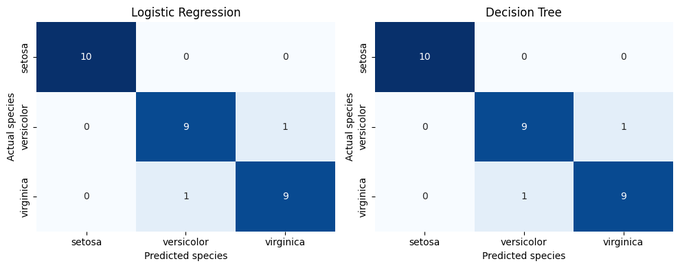

In [20]:
import numpy as np
from matplotlib.colors import ListedColormap
from sklearn.metrics import confusion_matrix

labels = ["setosa", "versicolor", "virginica"]

# One heatmap per model, counted on the 30 test flowers
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2))
for ax, y_pred, title in zip(
    axes,
    [y_pred_log, y_pred_tree],
    ["Logistic Regression", "Decision Tree"],
):
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=labels,
        yticklabels=labels,
        ax=ax,
    )
    ax.set_xlabel("Predicted species")
    ax.set_ylabel("Actual species")
    ax.set_title(title)

plt.tight_layout()
plt.show()


### What the heatmaps show

Both matrices are the same on this split.

- All 10 setosa flowers are on the diagonal. Nothing else was called setosa.
- 9 versicolor flowers are correct, and 1 versicolor was called virginica.
- 9 virginica flowers are correct, and 1 virginica was called versicolor.

That is 28 correct and 2 swaps between versicolor and virginica, which is why every score in Section 5 was 0.933 and setosa was 1.00.


### Decision boundary

The trained models use four measurements, and a four-measurement boundary cannot be drawn on a flat page. Petal length and petal width did most of the separating in the pairplot, so this picture uses only those two.

I fit a new Logistic Regression and a new Decision Tree on the training rows, using just the two petal columns, scaled with a `StandardScaler` fit on those training rows. The shaded color is the species the model would predict in that part of the plot. The dots are the 120 training flowers.

The scores in Section 5 still come from the four-measurement models. This plot is only the picture.


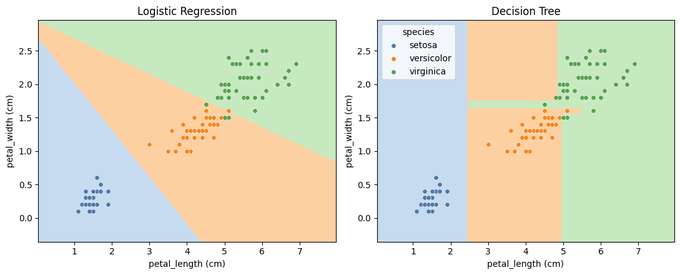

In [21]:
# Two petal measurements only, so the boundary can be drawn
petal_cols = ["petal_length", "petal_width"]
X_train_petal = X_train[petal_cols]

petal_scaler = StandardScaler()
X_train_petal_scaled = petal_scaler.fit_transform(X_train_petal)

log_reg_petal = LogisticRegression(random_state=42)
tree_petal = DecisionTreeClassifier(random_state=42)
log_reg_petal.fit(X_train_petal_scaled, y_train)
tree_petal.fit(X_train_petal_scaled, y_train)

point_colors = ["#4C78A8", "#F58518", "#54A24B"]
region_colors = ListedColormap(["#c6dbef", "#fdd0a2", "#c7e9c0"])

def plot_boundary(model, title, ax):
    x_min = X_train_petal_scaled[:, 0].min() - 0.6
    x_max = X_train_petal_scaled[:, 0].max() + 0.6
    y_min = X_train_petal_scaled[:, 1].min() - 0.6
    y_max = X_train_petal_scaled[:, 1].max() + 0.6
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 400),
        np.linspace(y_min, y_max, 400),
    )
    class_to_num = {name: i for i, name in enumerate(model.classes_)}
    pred = model.predict(np.c_[xx.ravel(), yy.ravel()])
    zz = np.array([class_to_num[name] for name in pred]).reshape(xx.shape)

    # Grid was built in scaled units. Put the axes back in cm.
    xx_cm = xx * petal_scaler.scale_[0] + petal_scaler.mean_[0]
    yy_cm = yy * petal_scaler.scale_[1] + petal_scaler.mean_[1]

    ax.contourf(
        xx_cm,
        yy_cm,
        zz,
        levels=np.arange(len(model.classes_) + 1) - 0.5,
        cmap=region_colors,
    )
    for species, color in zip(labels, point_colors):
        mask = y_train.to_numpy() == species
        ax.scatter(
            X_train_petal.loc[mask, "petal_length"],
            X_train_petal.loc[mask, "petal_width"],
            c=color,
            s=28,
            edgecolor="white",
            linewidth=0.4,
            label=species,
        )
    ax.set_xlabel("petal_length (cm)")
    ax.set_ylabel("petal_width (cm)")
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.4))
plot_boundary(log_reg_petal, "Logistic Regression", axes[0])
plot_boundary(tree_petal, "Decision Tree", axes[1])
axes[1].legend(title="species")
plt.tight_layout()
plt.show()


### What the boundary shows

On the logistic plot the regions meet in straight edges. Petals shorter than about 2.5 cm are setosa, in the bottom-left. Long, wide petals are virginica. Versicolor is the band between them. A few dots near those edges sit on the other color. Those are the flowers this two-petal model would mix up.

On the tree plot the regions are boxes. Every edge is horizontal or vertical, because each question cuts one measurement. The left box, petal length below about 2.5 cm, is setosa. The rest is split into versicolor and virginica, including a thin green strip through the orange area. That strip is one of the tree's cutoffs.
